# Member 4 — Deep learning: MLP and LSTM
Module: `src/models_deep.py` (PyTorch).

* **MLP**: 3 hidden layers (128-64-32), BatchNorm, ReLU, Dropout 0.3, AdamW, early stopping on validation PR-AUC.
* **LSTM**: 2-layer LSTM (64 units) over the user's last 5 transactions; the head also sees the current transaction.
* Each configuration is trained with 3 seeds; mean ± sd is reported.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
def show(name): display(Image(filename=str(C.FIG_DIR / f'{name}.png')))
def tbl(name): return pd.read_csv(C.TABLE_DIR / f'{name}.csv')

In [2]:
from src.features import prepare_dataset
from src.splits import get_split
from src.models_deep import TorchClassifier, build_sequences
from sklearn.metrics import average_precision_score
import joblib
meta = json.loads((C.MODELS_DIR / 'model_meta.json').read_text())
df = prepare_dataset(); split = get_split(df); y = df.is_fraud.values

## 1. What an LSTM input looks like
One row = one transaction + up to 4 earlier transactions of the same user (left-aligned, zero-padded).

In [3]:
sc = joblib.load(C.MODELS_DIR / 'lstm_scaler.joblib')
F = sc.transform(df[C.BEHAVIOURAL_COLS].values).astype('float32')
S, L = build_sequences(df, F)
print('tensor shape (transactions, steps, features):', S.shape)
print('sequence-length distribution:', dict(zip(*np.unique(L, return_counts=True))))
i = int(np.where(L == 5)[0][0]); pd.DataFrame(S[i], columns=C.BEHAVIOURAL_COLS).round(2)

tensor shape (transactions, steps, features): (26393, 5, 12)
sequence-length distribution: {np.int64(1): np.int64(4818), np.int64(2): np.int64(4702), np.int64(3): np.int64(4333), np.int64(4): np.int64(3775), np.int64(5): np.int64(8765)}


,amount,session_duration,transaction_amount_vs_sender_history,transaction_time_of_day,input_timing_consistency,app_switching_frequency,keyboard_input_speed,input_pause_patterns,screen_active_time,background_data_usage,pin_entry_speed,request_amount_roundness
0,-0.31,3.05,-0.36,-1.27,-5.49,8.11,-1.76,5.70,3.48,5.24,-1.95,-1.97
1,-0.12,1.22,-0.30,-1.27,-0.23,-0.14,-0.03,-0.63,-0.97,-0.58,0.07,-0.09
2,-0.05,1.48,-0.29,-1.13,-0.52,-0.73,-1.30,-0.78,1.63,0.18,-0.79,-0.09
3,1.98,-0.82,-0.13,-0.84,-1.11,0.45,-2.20,-0.45,-1.93,-0.19,-2.14,0.49
4,0.06,-0.87,-0.27,-0.28,-0.43,-0.73,0.55,-0.55,-0.29,0.27,0.57,-0.09


## 2. Short demonstration training of an MLP (verbose)

In [4]:
X = df[meta['feature_columns']].values.astype('float32')
demo = TorchClassifier('mlp', strategy='class_weight', epochs=8, verbose=True)
demo.fit(X[split['train']], y[split['train']], X[split['val']], y[split['val']])

epoch   1 loss 0.7542 val PR-AUC 0.8620


epoch   2 loss 0.5432 val PR-AUC 0.8886


epoch   3 loss 0.4628 val PR-AUC 0.9053


epoch   4 loss 0.4296 val PR-AUC 0.9132


epoch   5 loss 0.4039 val PR-AUC 0.9155


epoch   6 loss 0.3881 val PR-AUC 0.9156


epoch   7 loss 0.3755 val PR-AUC 0.9171


epoch   8 loss 0.3721 val PR-AUC 0.9168


## 3. Evaluate the saved models on the test set

In [5]:
mlp = TorchClassifier.load(C.MODELS_DIR / 'mlp.pt'); lstm = TorchClassifier.load(C.MODELS_DIR / 'lstm.pt')
te = split['test']
print('MLP  test PR-AUC:', round(average_precision_score(y[te], mlp.predict_proba(X[te])), 4))
print('LSTM test PR-AUC:', round(average_precision_score(y[te], lstm.predict_proba(S[te], L[te])), 4))

MLP  test PR-AUC: 0.942
LSTM test PR-AUC: 0.9305


## 4. Experiment 6 — does transaction order carry signal?

In [6]:
tbl('exp6_sequence_summary')

,model,setting,pr_auc_mean,pr_auc_std,roc_auc_mean,f1_mean,recall_mean,precision_mean
0,MLP,current transaction only (T2),0.9399,0.0032,0.9623,0.9145,0.8564,0.9809
1,MLP,current + history aggregates (T2H),0.9371,0.0008,0.9591,0.9092,0.8540,0.9723
2,LSTM,sequence length 1 (no history),0.9395,0.0002,0.9599,0.9187,0.8620,0.9834
3,LSTM,"last 5 transactions, ordered",0.9331,0.0028,0.9550,0.9021,0.8471,0.9651
4,LSTM,"last 5 transactions, history shuffled",0.9295,0.0027,0.9533,0.8983,0.8339,0.9737


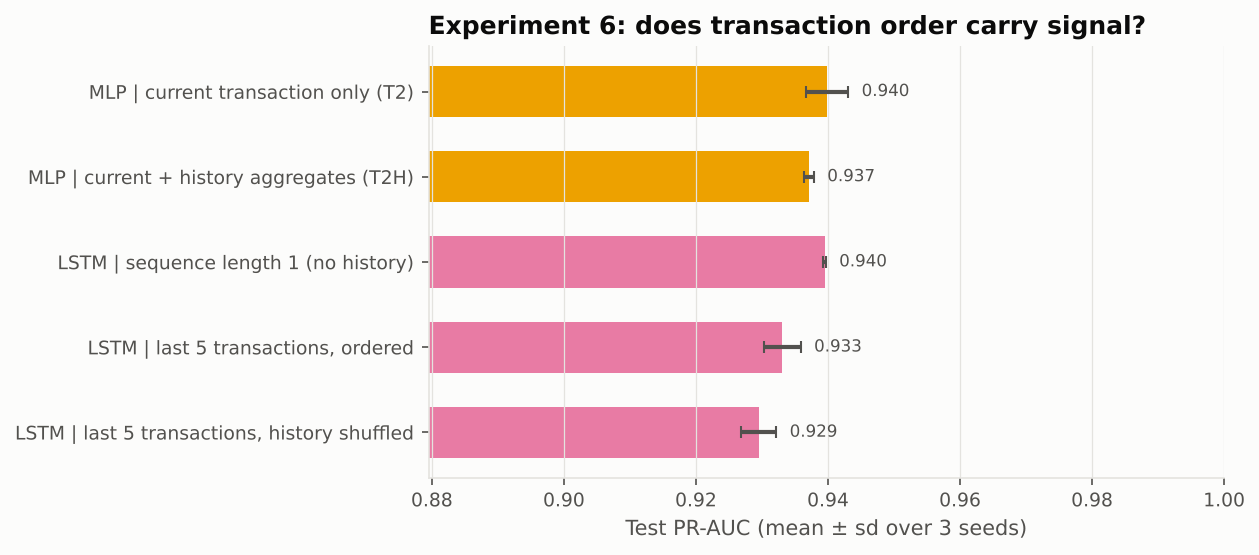

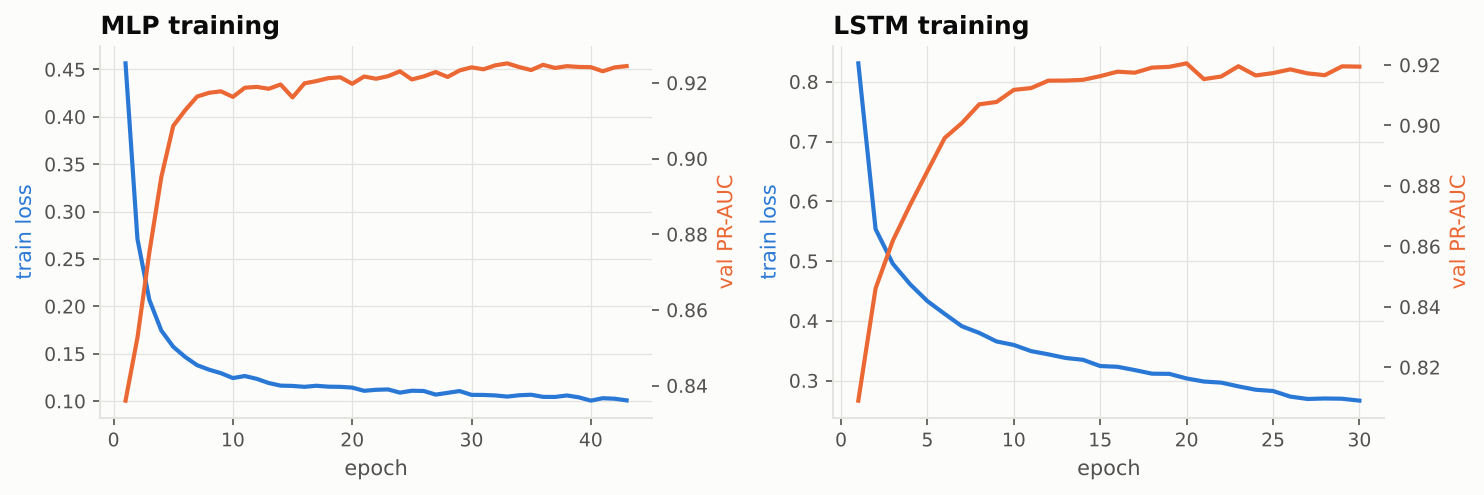

In [7]:
show('14_exp6_sequence'); show('15_dl_training_curves')

In [8]:
tbl('exp6_sequence_runs')[['model','setting','seed','epochs','val_pr_auc','pr_auc','recall','precision']]

,model,setting,seed,epochs,val_pr_auc,pr_auc,recall,precision
0,MLP,current transaction only (T2),42,55,0.9295,0.9420,0.8571,0.9821
1,MLP,current transaction only (T2),7,26,0.9221,0.9362,0.8582,0.9751
2,MLP,current transaction only (T2),2024,57,0.9259,0.9414,0.8540,0.9856
3,MLP,current + history aggregates (T2H),42,50,0.9249,0.9376,0.8509,0.9867
4,MLP,current + history aggregates (T2H),7,36,0.9221,0.9362,0.8634,0.9495
5,MLP,current + history aggregates (T2H),2024,43,0.9252,0.9374,0.8478,0.9807
6,LSTM,sequence length 1 (no history),42,38,0.9263,0.9393,0.8582,0.9856
7,LSTM,sequence length 1 (no history),7,51,0.9273,0.9395,0.8634,0.9881
8,LSTM,sequence length 1 (no history),2024,60,0.9276,0.9396,0.8644,0.9764
9,LSTM,"last 5 transactions, ordered",42,35,0.9202,0.9361,0.8582,0.9482


**Interpretation guide.** If *ordered ≈ shuffled*, order carries no extra signal. If *sequence length 1 ≥ length 5*, earlier transactions add noise rather than information — consistent with a generator that labels transactions independently of the user's history.